# Занятие 2. Подготовка данных, EDA и простые прогнозы

In [28]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from statsmodels.tsa.seasonal import STL

Для рисования графиков будем использовать Plotly. 

Несколько полезных ссылок:
- Вводная статья про Plotly (на русском): https://habr.com/ru/articles/502958/.

- Галерея графиков с примерами кода: https://plotly.com/python/. 
  
- Time Series and Date Axes in Python: https://plotly.com/python/time-series/.

## 0. Компоненты временного ряда

| Компонента | На какой вопрос отвечает? | Пример |
| --- | --- | --- |
| **Тренд** | Как меняется общий уровень на длинном промежутке? | Продажи постепенно растут. |
| **Сезонность** | Что повторяется с известным периодом $m$? | Каждую субботу продажи выше. |
| **Остаток** | Что не объяснили тренд и сезонность? | Необычный всплеск в отдельный день. |

### 0.1. Тренд: как меняется общий уровень?

- **Постоянный уровень:** направленного изменения нет.
- **Линейный рост:** за день прибавляется одинаковое количество.
- **Рост с ускорением:** за день прибавляется одинаковый процент, поэтому абсолютная прибавка растёт.
- **Затухающий рост:** прибавка постепенно уменьшается, а уровень приближается к плато.

### 0.2. Сезонность: что повторяется?
- В одном ряде может быть **несколько сезонностей**, например суточная и недельная у почасовых данных.
- Не любое волнообразное движение сезонно: у **циклов** длина подъёмов и спадов может меняться.

Запись ряда как суммы компонент называется **аддитивной**.

$$y_t = T_t + S_t + R_t.$$

Здесь:
- $y_t$ — значение ряда в день $t$;
- $T_t$ — уровень, заданный трендом;
- $S_t$ — сезонная прибавка или убавка;
- $R_t$ — остаток.

Если величина сезонных колебаний увеличивается вместе с уровнем, их удобно описывать
в процентах от уровня. Тогда запись ряда как произведения компонент называется **мультипликативной**.

$$y_t = T_t \cdot S_t \cdot R_t.$$

Здесь:
- $y_t$ — значение ряда в день $t$;
- $T_t$ — уровень в исходных единицах;
- $S_t$ — сезонный множитель: например, $1{,}12$ означает +12%, а $0{,}88$ означает −12%;
- $R_t$ — множитель остаточного отклонения: например, $0{,}98$ означает ещё −2%.

`Вопрос`:

<details>
<summary>Как легко перейти из мультипликативной записи в аддитивную?</summary>

Для этого нужно взять логарифмы от всех компонент:
$$log(y_t) = log(T_t) + log(S_t) + log(R_t).$$

</details>

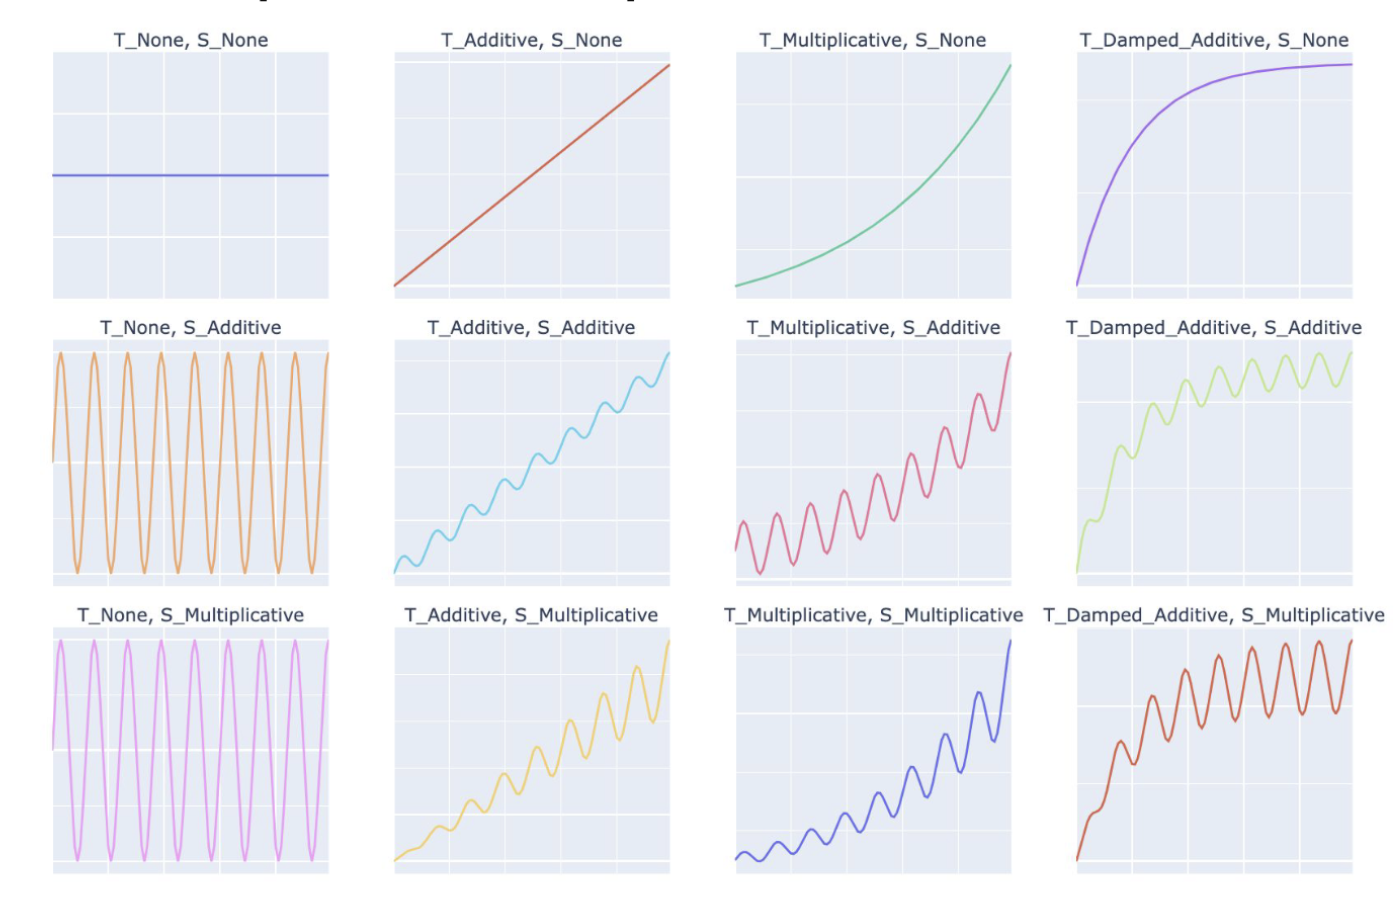

## 1. Сетап задачи

In [29]:
SEED = 42
H = 28
PERIOD = 7  # недельная сезонность при дневных наблюдениях
DATES = pd.date_range("2025-01-01", periods=364, freq="D")
ORIGIN = DATES[-H-1]  # последний известный день

print("Начало и конец временного ряда: ", DATES[0].date(), "-", DATES[-1].date())
print("Момент расчёта: ", ORIGIN.date())
print("Горизонт:", DATES[-H].date(), "—", DATES[-1].date(), f"({H} дней)")

Начало и конец временного ряда:  2025-01-01 - 2025-12-30
Момент расчёта:  2025-12-02
Горизонт: 2025-12-03 — 2025-12-30 (28 дней)


In [30]:
def make_demo_data(seed=42):
    rng = np.random.default_rng(seed)
    # Недельная сезонность — насколько продажи отличаются от среднего в неделю
    weekday = np.array([-8, -6, -4, -2, 6, 18, 10])
    frames = []
    # Ряды не выровнены
    for store, start, stop, level in [("A", 0, 364, 55), ("B", 28, 357, 85), ("C", 56, 364, 115)]:
        t = np.arange(start, stop)
        dates = DATES[start:stop]
        trend = level + 0.045 * t
        # У A и B рост сначала быстрый, затем постепенно замедляется.
        if store in ["A", "B"]:
            age = t - start  # сколько дней прошло с открытия магазина
            trend = level + 50 * (1 - np.exp(-age / 100))
        season = weekday[dates.day_of_week]
        # У A амплитуда недели постоянна, у B она растёт вместе с уровнем
        if store == "B":
            season = season * trend / level
        # У магазина C сдвиг вверх на 35 упаковок в день после 200-го дня
        shift = 35 * (t >= 200) if store == "C" else 0
        values = np.rint(trend + season + shift + rng.normal(0, 2, len(t)))
        values[t == 215] += 35  # настоящая акция, а не ошибка
        frames.append(pd.DataFrame({"id": store, "timestamp": dates, "value": values}))
    return pd.concat(frames, ignore_index=True)


def series_for(data, store, column="value"):
    """Выбирает ряд из таблицы по магазину и возвращает его в виде Series"""
    rows = data[data["id"] == store]
    rows = rows.sort_values("timestamp")
    rows = rows.set_index("timestamp")
    return rows[column]


complete = make_demo_data(SEED)
# ground truth для задачи восстановления пропусков
history_truth = complete.loc[complete.timestamp <= ORIGIN].copy()
history = history_truth.copy()
test_df = complete.loc[complete.timestamp > ORIGIN].copy()

# Определяем границы пропусков
GAPS = {
    "A — неделя": ("A", DATES[98], DATES[104]),
    "B — три недели; мультипликативная сезонность": ("B", DATES[154], DATES[174]),
    "C — неделя; смена режима": ("C", DATES[198], DATES[204]),
}
# Делаем сами пропуски
for store, start, stop in GAPS.values():
    mask = (history.id == store) & history.timestamp.between(start, stop)
    history.loc[mask, "value"] = np.nan

observed = history.sort_values(["id", "timestamp"]).reset_index(drop=True)
truth = history_truth.sort_values(["id", "timestamp"]).reset_index(drop=True)

print("observed")
display(observed)
print("truth")
display(truth)
print("test_df")
display(test_df)

observed


,id,timestamp,value
0,A,2025-01-01,52.0
1,A,2025-01-02,51.0
2,A,2025-01-03,63.0
3,A,2025-01-04,76.0
4,A,2025-01-05,63.0
...,...,...,...
919,C,2025-11-28,173.0
920,C,2025-11-29,183.0
921,C,2025-11-30,174.0
922,C,2025-12-01,157.0


truth


,id,timestamp,value
0,A,2025-01-01,52.0
1,A,2025-01-02,51.0
2,A,2025-01-03,63.0
3,A,2025-01-04,76.0
4,A,2025-01-05,63.0
...,...,...,...
919,C,2025-11-28,173.0
920,C,2025-11-29,183.0
921,C,2025-11-30,174.0
922,C,2025-12-01,157.0


test_df


,id,timestamp,value
336,A,2025-12-03,98.0
337,A,2025-12-04,102.0
338,A,2025-12-05,112.0
339,A,2025-12-06,123.0
340,A,2025-12-07,109.0
...,...,...,...
996,C,2025-12-26,174.0
997,C,2025-12-27,184.0
998,C,2025-12-28,177.0
999,C,2025-12-29,160.0


In [31]:
fig = make_subplots(
    rows=3, cols=1, shared_xaxes=True, subplot_titles=[
        "A: затухающий рост, аддитивная сезонность; пропуск — неделя",
        "B: затухающий рост, мультипликативная сезонность; пропуск — три недели",
        "C: пропуск — неделя на смене режима",
    ]
)
for row, (store, color) in enumerate(zip(["A", "B", "C"], ["blue", "teal", "purple"]), start=1):
    s = series_for(observed, store)
    fig.add_trace(
        go.Scatter(
            x=s.index, y=s, line_color=color, connectgaps=False, name=store, showlegend=False
        ),
        row=row,
        col=1,
    )
    for name, (gap_store, start, stop) in GAPS.items():
        if store == gap_store:
            fig.add_vrect(
                x0=start - pd.Timedelta(hours=12),
                x1=stop + pd.Timedelta(hours=12),
                fillcolor="orange",
                opacity=0.13,
                line_width=0,
                row=row,
                col=1,
            )

fig.update_layout(
    template="plotly_white",
    height=700,
    font=dict(size=13, family="Arial"),
    margin=dict(l=60, r=30, t=80, b=90),
    hovermode="x unified",
    legend=dict(orientation="h", y=-0.20),
)
fig.update_yaxes(title_text="Продажи, упаковок / день", gridcolor="#EDF1F5")
fig.update_xaxes(title_text="", gridcolor="#EDF1F5")
fig.update_xaxes(title_text="Дата", row=3, col=1)
fig.show()

`Вопрос`:

__Что можно сказать про эти временные ряды?__
- Различаются ли ряды между собой?

__Выберите какой-то один ряд и посмотрите на него более подробно.__
- Есть ли в нем тренд (линейный, экспоненциальный или какой-то другой)?
- Есть ли в нем сезонность (аддитивная или мультипликативная)?
- Есть ли в нем точки смены режима (точки, в которых сильно меняется поведение ряда)?
- Есть ли в нем выбросы?

## 2. Заполнение пропусков

**Что именно произошло?**

- Магазин был закрыт — продажи равняются нулю.
- Не пришли измерения — можно оценивать по соседним наблюдениям.
- Не было товара — низкие продажи не равны низкому спросу: задача восстановления спроса сложнее.

Дальше считаем, что нам не пришли измерения и мы будем оценивать их по соседним наблюдениям.

**Какие данные нам доступны?**
- Восстанавливаем старую неделю сегодня — известны наблюдения до и после неё. Правый край — «будущее» относительно пропуска, но уже прошлое относительно текущего расчёта, и его использование допустимо для ретроспективного восстановления истории.
- Заполняем значение по мере поступления данных — известны наблюдения до, но неизвестны наблюдения после. Тогда мы можем опираться только на доступные предыдущие наблюдения.

Лучший метод при двух известных краях может оказаться неприменим в момент, когда правого края ещё не было.

`Вопрос`: Какой магазин будет сложнее восстанавливать при пропусках? Почему?

### 2.1. Последнее известное значение:

Заполняем пропуск последним известным значением до него:

$$\hat y_t = y_{t_L}.$$

Здесь:

- $\hat y_t$ — значение, которым заполняем пропуск;
- $y_{t_L}$ — последнее известное значение (left).

In [32]:
filled_ffill = observed.copy()
filled_ffill["value"] = filled_ffill.groupby("id")["value"].ffill()

`Вопрос:`

Зачем здесь groupby("id")?

### 2.2. Тот же день предыдущей недели:

Для дневного ряда с недельной сезонностью используем значение семь дней назад:

$$\hat y_t = y^*_{t-m}, \qquad m=7.$$

Здесь:

- $m$ — сезонный период;
- $y^*_{t-m}$ — наблюдаемое или уже восстановленное значение в тот же день недели на предыдущей неделе.

In [33]:
filled_seasonal = observed.copy()

# Самый длинный пропуск в данных — 3 недели
for week in range(3):
    # Сдвигаем значения на 7 дней назад
    week_ago = filled_seasonal.groupby("id")["value"].shift(7)
    # Заполняем только пропуски
    filled_seasonal["value"] = filled_seasonal["value"].fillna(week_ago)

### 2.3. Среднее для этого дня недели:

Берём наблюдённые значения за тот же день недели в предыдущие восемь недель
и считаем их среднее:

$$\hat y_t = \frac{1}{n_t}\sum_{i=1}^{n_t} y_{s_i}.$$

Здесь:

- $y_{s_i}$ — наблюдаемое значение в дату $s_i$ (одного из доступных наблюдений за тот же день недели в предыдущие восемь недель);
- $n_t$ — число таких наблюдений (не больше восьми);

`Вопрос`:

<details>
<summary>Почему такой вариант может быть плохим?</summary>

- При изменении тренда среднее смешивает старые и новые условия.
- Сильный шум или выброс одного дня может исказить среднее.
- После смены режима среднее некоторое время учитывает данные старого режима.

</details>

In [34]:
filled_weekday_mean = observed.copy()

for store, shop in observed.groupby("id"):
    missing_rows = shop[shop["value"].isna()]
    for row in missing_rows.index:
        date = shop.loc[row, "timestamp"]
        # Сдвигаемся на 8 недель назад
        start = date - pd.Timedelta(weeks=8)
        past = shop[shop["timestamp"] >= start]
        past = past[past["timestamp"] < date]
        # Выбираем только дни, которые соответствуют тому же дню недели
        same_day = past[past["timestamp"].dt.day_of_week == date.day_of_week]
        # И считаем по ним среднее
        filled_weekday_mean.loc[row, "value"] = same_day["value"].mean()

### 2.4. Первое известное значение после пропуска:

`bfill`: переносим назад первое известное значение после пропуска:

$$\hat y_t = y_{t_R}.$$

Здесь:

- $y_{t_R}$ — первое известное значение после пропуска (right).

**warning**: этот метод может привести к утечке информации из будущего.

In [35]:
filled_bfill = observed.copy()
filled_bfill["value"] = filled_bfill.groupby("id")["value"].bfill()

### 2.5. Линейная интерполяция:

Соединяем ближайшие известные значения до и после пропуска прямой:

$$\hat y_t=y_L+\frac{t-t_L}{t_R-t_L}(y_R-y_L),\qquad t_L<t<t_R.$$

Здесь:

- $t_L$ и $t_R$ — ближайшие даты с наблюдениями слева и справа от пропуска;
- $y_L$ и $y_R$ — наблюдаемые значения в эти даты;
- $t-t_L$ — время от левого края до восстанавливаемого дня;
- $t_R-t_L$ — время между двумя известными краями.

Доля $\frac{t-t_L}{t_R-t_L}$ показывает, какую часть пути от левого края к правому
мы прошли. Например, посередине интервала получим среднее двух крайних значений.

**warning**: этот метод может привести к утечке информации из будущего.

In [36]:
filled_linear = observed.copy()
filled_linear = observed.set_index("timestamp")

for store in observed["id"].unique():
    rows = filled_linear["id"] == store
    values = filled_linear.loc[rows, "value"]
    # method="time" учитывает расстояния между датами
    # limit_area="inside" заполняет пропуск, только если есть известные значения и до него, и после него
    filled_linear.loc[rows, "value"] = values.interpolate(
        method="time", limit_area="inside"
    )

filled_linear = filled_linear.reset_index()
filled_linear = filled_linear[["id", "timestamp", "value"]]

### 2.6. Интерполяция отдельно по дням недели:

Соединим известную субботу **до** пропуска с известной субботой **после** него.
Повторим это для каждого дня недели. Формула та же, но известные края выбираем
только среди наблюдений за **тот же день недели**, что и пропуск:

$$\hat y_t=y_L+\frac{t-t_L}{t_R-t_L}(y_R-y_L),\qquad t_L<t<t_R.$$

Здесь:

- $t_L$ — ближайшая известная дата **до** $t$ с тем же днём недели;
- $t_R$ — ближайшая известная дата **после** $t$ с тем же днём недели;
- $y_L$ и $y_R$ — наблюдённые значения в эти даты;
- $t-t_L$ и $t_R-t_L$ — время от левого края до $t$ и между двумя краями.

**warning**: этот метод может привести к утечке информации из будущего.

In [37]:
filled_seasonal_interpolation = observed.copy()
filled_seasonal_interpolation = observed.set_index("timestamp")
filled_seasonal_interpolation["weekday"] = filled_seasonal_interpolation.index.day_of_week

for store in observed["id"].unique():
    for day in range(7):
        rows = filled_seasonal_interpolation["id"] == store
        rows = rows & (filled_seasonal_interpolation["weekday"] == day)
        values = filled_seasonal_interpolation.loc[rows, "value"]
        filled_seasonal_interpolation.loc[rows, "value"] = values.interpolate(
            method="time", limit_area="inside"
        )

filled_seasonal_interpolation = filled_seasonal_interpolation.reset_index()
filled_seasonal_interpolation = filled_seasonal_interpolation[["id", "timestamp", "value"]]

### Сравним методы

In [38]:
filled_ffill["method"] = "ffill"
filled_seasonal["method"] = "Неделя назад"
filled_weekday_mean["method"] = "Среднее по дню недели"
filled_bfill["method"] = "bfill"
filled_linear["method"] = "Линейная"
filled_seasonal_interpolation["method"] = "Сезонная интерполяция"

filled = pd.concat(
    [
        filled_ffill,
        filled_seasonal,
        filled_weekday_mean,
        filled_bfill,
        filled_linear,
        filled_seasonal_interpolation,
    ],
    ignore_index=True,
)

INTERNAL_GAPS = ["A — неделя", "B — три недели; мультипликативная сезонность", "C — неделя; смена режима"]

In [39]:
def compare_gap(store, start, stop, title):
    s = series_for(observed, store)
    reference = series_for(truth, store)
    estimates = filled[filled["id"] == store]
    estimates = estimates.pivot(index="timestamp", columns="method", values="value")
    estimates = estimates[list(filled["method"].unique())]
    window = slice(start - pd.Timedelta(days=14), stop + pd.Timedelta(days=14))
    hidden = s.index[(s.index >= start) & (s.index <= stop)]
    fig = make_subplots(
        rows=1, cols=2, subplot_titles=["Только прошлое", "С известным правым краем"]
    )
    groups = [list(estimates.columns[:3]), list(estimates.columns[3:])]
    # Свои цвета для методов на каждой панели.
    colors = [["royalblue", "seagreen", "darkorange"],
              ["crimson", "purple", "saddlebrown"]]
    for col, names in enumerate(groups, start=1):
        fig.add_trace(
            go.Scatter(
                x=s.loc[window].index,
                y=s.loc[window],
                mode="lines+markers",
                line_color="#17324F",
                name="Наблюдения",
                legendgroup="observed",
                showlegend=col == 1,
                connectgaps=False,
            ),
            row=1,
            col=col,
        )
        fig.add_trace(
            go.Scatter(
                x=hidden,
                y=reference.loc[hidden],
                line=dict(color="gray", dash="dash"),
                name="Скрытый эталон",
                visible="legendonly",
                legendgroup="truth",
                showlegend=col == 1,
            ),
            row=1,
            col=col,
        )
        for name, color in zip(names, colors[col - 1]):
            fig.add_trace(
                go.Scatter(
                    x=hidden,
                    y=estimates.loc[hidden, name],
                    name=name,
                    visible="legendonly",
                    mode="lines+markers",
                    line_color=color,
                ),
                row=1,
                col=col,
            )
        fig.add_vrect(
            x0=start - pd.Timedelta(hours=12),
            x1=stop + pd.Timedelta(hours=12),
            fillcolor="orange",
            opacity=0.10,
            line_width=0,
            row=1,
            col=col,
        )
    fig.update_layout(
        template="plotly_white",
        title=title,
        height=470,
        margin=dict(l=50, r=25, t=85, b=125),
        hovermode="x unified",
        legend=dict(orientation="h", y=-0.30, font=dict(size=10)),
    )
    fig.update_yaxes(title_text="Упаковок / день")
    fig.update_xaxes(title_text="Дата")
    fig.show()


for name in INTERNAL_GAPS:
    store, start, stop = GAPS[name]
    compare_gap(store, start, stop, title=name)

### Как проверить восстановление, если в реальном пропуске нет ответа?

В нашем примере эталонные ответы известны: мы сохранили исходные продажи в `truth`,
а затем искусственно создали пропуски в `observed`. Теперь используем их для проверки результата.

Считаем MAE **только на скрытых точках**:
$$\mathrm{MAE}_{gap}=\frac{1}{|G|}\sum_{t\in G}|y_t-\hat y_t|,$$
где $G$ — скрытый интервал, $y_t$ — эталон, а $\hat y_t$ — восстановленное значение.
Ошибка по всей истории была бы занижена: на известных точках мы оставили исходные значения.

В реальном пропуске правильного ответа нет. Вместо этого:

1. Случайно выбираем несколько фрагментов с известными значениями и сохраняем ответы.
2. Временно скрываем эти фрагменты и заново заполняем пропуски каждым методом.
3. Считаем ошибку на скрытых точках.
4. Повторяем эксперимент с другими фрагментами и сравниваем среднюю ошибку и её разброс.

In [40]:
gap_scores = pd.DataFrame(index=filled["method"].unique())
gap_scores.index.name = "Метод"
actual = truth.rename(columns={"value": "actual"})

for gap_name in INTERNAL_GAPS:
    store, gap_start, gap_stop = GAPS[gap_name]

    # Выбираем восстановленные значения внутри одного пропуска.
    gap = filled[filled["id"] == store]
    gap = gap[gap["timestamp"].between(gap_start, gap_stop)]

    # Добавляем эталон и считаем абсолютную ошибку.
    gap = gap.merge(actual, on=["id", "timestamp"])
    gap["abs_error"] = (gap["value"] - gap["actual"]).abs()

    # Записываем MAE каждого метода в колонку этого пропуска.
    gap_scores[gap_name] = gap.groupby("method")["abs_error"].mean()


display(gap_scores.round(2))

,A — неделя,B — три недели; мультипликативная сезонность,C — неделя; смена режима
Метод,,,
ffill,10.71,12.81,32.00
Неделя назад,3.00,3.00,28.00
Среднее по дню недели,7.32,4.90,27.82
bfill,7.43,11.86,17.86
Линейная,9.39,12.47,9.18
Сезонная интерполяция,1.50,2.05,18.79


In [41]:
fig = go.Figure()
for gap_name, color in zip(INTERNAL_GAPS, ["royalblue", "darkorange", "seagreen"]):
    fig.add_trace(
        go.Bar(
            x=gap_scores.index,
            y=gap_scores[gap_name],
            name=gap_name,
            marker_color=color,
        )
    )

fig.update_layout(
    template="plotly_white",
    title="MAE на трёх скрытых фрагментах",
    barmode="group",
    bargap=0.25,
    bargroupgap=0.10,
    height=460,
    margin=dict(l=60, r=25, t=85, b=110),
    legend=dict(orientation="h", y=1.12),
)
fig.update_xaxes(title_text="Способ заполнения", tickangle=-12)
fig.update_yaxes(title_text="MAE, упаковок / день")
fig.show()

Из честных методов лучше всего работает `filled_seasonal`. В дальнейшем мы будем использовать его.

In [42]:
train_df = filled_seasonal.copy()

### А как ещё можно заполнить пропуски?

| Подход | Идея |
| --- | --- |
| **Другие виды интерполяции** | Провести между известными точками гладкую кривую, например сплайн. |
| **Модели прогноза** | Предсказывать пропущенные значения по доступному прошлому. |
| **Модели пространства состояний** | Описать скрытый уровень и сезонность, а затем оценить их на датах с пропусками. |
| **Генеративные модели** | Научиться создавать правдоподобные заполнения с учётом известной части ряда. |

## 3. EDA: какие закономерности помогут построить прогноз?

In [43]:
missing_points = observed[observed["value"].isna()]
restored_points = train_df.merge(missing_points[["id", "timestamp"]], on=["id", "timestamp"])
display(restored_points.head())

fig = make_subplots(
    rows=3, cols=1, shared_xaxes=True, subplot_titles=["Магазин A", "Магазин B", "Магазин C"]
)
for row, (store, shop) in enumerate(train_df.groupby("id"), start=1):
    fig.add_trace(
        go.Scatter(
            x=shop["timestamp"],
            y=shop["value"],
            name="История",
            line_color="royalblue",
            legendgroup="history",
            showlegend=row == 1,
        ),
        row=row,
        col=1,
    )
    restored = restored_points[restored_points["id"] == store]
    fig.add_trace(
        go.Scatter(
            x=restored["timestamp"],
            y=restored["value"],
            mode="markers",
            name="Восстановлено",
            marker_color="darkorange",
            legendgroup="filled",
            showlegend=row == 1,
        ),
        row=row,
        col=1,
    )
fig.update_layout(
    template="plotly_white",
    height=700,
    hovermode="x unified",
    legend=dict(orientation="h", y=-0.12),
)
fig.update_yaxes(title_text="Упаковок / день")
fig.update_xaxes(title_text="Дата", row=3, col=1)
fig.show()

,id,timestamp,value,method
0,A,2025-04-09,81.0,Неделя назад
1,A,2025-04-10,82.0,Неделя назад
2,A,2025-04-11,91.0,Неделя назад
3,A,2025-04-12,100.0,Неделя назад
4,A,2025-04-13,93.0,Неделя назад


### 3.1. Есть ли тренд?

In [44]:
rolling_stats = train_df.copy()
rolling_stats["mean_28"] = np.nan

for store, shop in train_df.groupby("id"):
    # center=True: окно расположено вокруг текущего дня.
    rolling_stats.loc[shop.index, "mean_28"] = shop["value"].rolling(28, center=True).mean()

display(rolling_stats.head(20))

,id,timestamp,value,method,mean_28
0,A,2025-01-01,52.0,Неделя назад,NaN
1,A,2025-01-02,51.0,Неделя назад,NaN
2,A,2025-01-03,63.0,Неделя назад,NaN
3,A,2025-01-04,76.0,Неделя назад,NaN
4,A,2025-01-05,63.0,Неделя назад,NaN
5,A,2025-01-06,47.0,Неделя назад,NaN
6,A,2025-01-07,52.0,Неделя назад,NaN
7,A,2025-01-08,54.0,Неделя назад,NaN
8,A,2025-01-09,57.0,Неделя назад,NaN
9,A,2025-01-10,64.0,Неделя назад,NaN


In [45]:
fig = make_subplots(
    rows=3, cols=1, shared_xaxes=True, subplot_titles=["Магазин A", "Магазин B", "Магазин C"]
)
for row, (store, shop) in enumerate(rolling_stats.groupby("id"), start=1):
    fig.add_trace(
        go.Scatter(
            x=shop["timestamp"],
            y=shop["value"],
            name="Продажи",
            line_color="lightsteelblue",
            legendgroup="sales",
            showlegend=row == 1,
        ),
        row=row,
        col=1,
    )
    fig.add_trace(
        go.Scatter(
            x=shop["timestamp"],
            y=shop["mean_28"],
            name="Среднее за 28 дней",
            line_color="darkorange",
            legendgroup="mean",
            showlegend=row == 1,
        ),
        row=row,
        col=1,
    )
fig.update_layout(
    template="plotly_white",
    title="Сглаживание помогает увидеть изменение уровня",
    height=700,
    hovermode="x unified",
    legend=dict(orientation="h", y=-0.12),
)
fig.update_yaxes(title_text="Упаковок / день")
fig.update_xaxes(title_text="Дата", row=3, col=1)
fig.show()

`Вопрос:`
Почему линия среднего отсутствует на краях?

### 3.2. Есть ли сезонность?

In [46]:
recent_history = train_df.groupby("id").tail(56).copy()
recent_history["weekday"] = recent_history["timestamp"].dt.day_of_week
display(recent_history.head())

,id,timestamp,value,method,weekday
280,A,2025-10-08,99.0,Неделя назад,2
281,A,2025-10-09,97.0,Неделя назад,3
282,A,2025-10-10,110.0,Неделя назад,4
283,A,2025-10-11,121.0,Неделя назад,5
284,A,2025-10-12,110.0,Неделя назад,6


In [47]:
for store, g in recent_history.groupby("id", sort=False):
    y = g.set_index("timestamp").value
    print(f"Магазин {store}")
    recent = y
    fig = make_subplots(
        rows=1, cols=2, subplot_titles=["Последние 8 недель", "Распределение по дням недели"]
    )
    fig.add_trace(
        go.Scatter(
            x=recent.index, y=recent, mode="lines+markers", line_color="blue", showlegend=False
        ),
        row=1,
        col=1,
    )
    weekdays = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
    for day, name in enumerate(weekdays):
        vals = g.loc[g["weekday"] == day, "value"]
        fig.add_trace(
            go.Box(y=vals, name=name, marker_color="teal", showlegend=False), row=1, col=2
        )
    fig.update_xaxes(type="category", categoryorder="array", categoryarray=weekdays, row=1, col=2)
    fig.update_layout(
        template="plotly_white",
        title=dict(
            text="Недельная сезонность: сначала гипотеза, затем профиль",
            font=dict(size=18, color="#17324F"),
        ),
        height=400,
        font=dict(size=13, family="Arial"),
        margin=dict(l=60, r=25, t=75, b=60),
        legend=dict(orientation="h", y=-0.22),
        hovermode="x unified",
    )
    fig.update_xaxes(title_text="Дата", showgrid=True, gridcolor="#EDF1F5")
    fig.update_xaxes(title_text="День недели", row=1, col=2)
    fig.update_yaxes(title_text="Продажи, упаковок / день", gridcolor="#EDF1F5")
    fig.update_layout(title_text=f"Магазин {store}: {fig.layout.title.text}")
    fig.show()

Магазин A


Магазин B


Магазин C


`Вопрос`:

<details><summary>В субботу продажи выше. Можем ли мы сказать, что это именно из-за дня недели?</summary>

Нет. Это описательная связь в истории. Профиль может смешиваться с трендом, акциями, праздниками и составом выборки. 

</details>

## 4. Декомпозиция на компоненты с помощью STL

STL разделяет историю на тренд, сезонность и остаток: https://www.statsmodels.org/dev/generated/statsmodels.tsa.seasonal.STL.html.

- Алгоритм LOWESS (на русском): http://www.machinelearning.ru/wiki/index.php?title=Алгоритм_LOWESS
  
- Ядровые функции (на русском): http://www.machinelearning.ru/wiki/index.php?title=Ядерное_сглаживание
  
- Метод наименьших квадратов (на русском): https://books.econ.msu.ru/Introduction-to-Econometrics/chap02/2.2/ 

- Метод наименьших квадратов в матричной форме (на русском): https://books.econ.msu.ru/Introduction-to-Econometrics/chap03/3.3/ 
  
- Основные методы декомпозиции и их сравнение: https://otexts.com/fpp3/decomposition.html

In [48]:
stl_components = train_df[["id", "timestamp", "value"]].copy()

for store, shop in train_df.groupby("id"):
    result = STL(shop["value"], period=PERIOD, seasonal=13, robust=True).fit()
    stl_components.loc[shop.index, "trend"] = result.trend
    stl_components.loc[shop.index, "seasonal"] = result.seasonal
    stl_components.loc[shop.index, "resid"] = result.resid

In [49]:
fig_columns = ["value", "trend", "seasonal", "resid"]
for store, shop in stl_components.groupby("id"):
    fig = make_subplots(
        rows=4,
        cols=1,
        shared_xaxes=True,
        subplot_titles=["Ряд", "Тренд", "Сезонность", "Остаток"],
        vertical_spacing=0.07,
    )
    for row, column in enumerate(fig_columns, start=1):
        fig.add_trace(
            go.Scatter(
                x=shop["timestamp"],
                y=shop[column],
                line_color=["blue", "teal", "orange", "purple"][row - 1],
                showlegend=False,
            ),
            row=row,
            col=1,
        )
    fig.update_layout(
        template="plotly_white",
        title=f"Магазин {store}: STL — компоненты ряда",
        height=850,
        hovermode="x unified",
    )
    fig.update_yaxes(title_text="Упаковок / день")
    fig.update_xaxes(title_text="Дата", row=4, col=1)
    fig.show()

## 5. Сделаем первый прогноз!

Тренд оставим на последнем уровне, сезонность повторим последней оценённой неделей.
Остаток прогнозируем нулём. Складываем:

$$\hat y_{t+h}=T_t+\hat S_{t+h},$$

где $T_t$ — последняя оценка тренда, а $\hat S_{t+h}$ — повтор сезонной компоненты.

In [50]:
forecast_frames = []
future_dates = pd.date_range(ORIGIN + pd.Timedelta(days=1), periods=H)

for store, shop in stl_components.groupby("id"):
    future = pd.DataFrame()
    future["timestamp"] = future_dates
    future["id"] = store
    future["trend"] = shop["trend"].iloc[-1]
    future["seasonal"] = shop["seasonal"].tail(7).tolist() * 4  # четыре недели
    future["value"] = future["trend"] + future["seasonal"]
    forecast_frames.append(future)

forecasts = pd.concat(forecast_frames, ignore_index=True)

In [51]:
fig = make_subplots(
    rows=3, cols=1, shared_xaxes=True, subplot_titles=["Магазин A", "Магазин B", "Магазин C"]
)
for row, (store, shop) in enumerate(train_df.groupby("id"), start=1):
    history_part = shop
    future = forecasts[forecasts["id"] == store]
    actual = test_df[test_df["id"] == store]
    fig.add_trace(
        go.Scatter(
            x=history_part["timestamp"],
            y=history_part["value"],
            name="История",
            line_color="royalblue",
            legendgroup="history",
            showlegend=row == 1,
        ),
        row=row,
        col=1,
    )
    fig.add_trace(
        go.Scatter(
            x=future["timestamp"],
            y=future["value"],
            name="Прогноз",
            line=dict(color="darkorange", dash="dash"),
            legendgroup="forecast",
            showlegend=row == 1,
        ),
        row=row,
        col=1,
    )
    fig.add_trace(
        go.Scatter(
            x=actual["timestamp"],
            y=actual["value"],
            name="Факт будущего",
            line_color="gray",
            visible="legendonly",
            legendgroup="actual",
            showlegend=row == 1,
        ),
        row=row,
        col=1,
    )
fig.update_layout(
    template="plotly_white",
    title="Последний уровень тренда + повтор сезонности",
    height=700,
    hovermode="x unified",
    legend=dict(orientation="h", y=-0.12),
)
fig.update_xaxes(title_text="Дата", row=3, col=1)
fig.update_yaxes(title_text="Упаковок / день")
fig.show()